In [2]:
# Import Libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

import warnings
warnings.filterwarnings('ignore')


# Load Dataset
df = pd.read_csv("hotel_bookings.csv")

print("Dataset Shape:", df.shape)
df.head()

Dataset Shape: (119390, 32)


,hotel,is_canceled,lead_time,arrival_date_year,arrival_date_month,arrival_date_week_number,arrival_date_day_of_month,stays_in_weekend_nights,stays_in_week_nights,adults,...,deposit_type,agent,company,days_in_waiting_list,customer_type,adr,required_car_parking_spaces,total_of_special_requests,reservation_status,reservation_status_date
0,Resort Hotel,0,342,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
1,Resort Hotel,0,737,2015,July,27,1,0,0,2,...,No Deposit,NaN,NaN,0,Transient,0.0,0,0,Check-Out,2015-07-01
2,Resort Hotel,0,7,2015,July,27,1,0,1,1,...,No Deposit,NaN,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
3,Resort Hotel,0,13,2015,July,27,1,0,1,1,...,No Deposit,304.0,NaN,0,Transient,75.0,0,0,Check-Out,2015-07-02
4,Resort Hotel,0,14,2015,July,27,1,0,2,2,...,No Deposit,240.0,NaN,0,Transient,98.0,0,1,Check-Out,2015-07-03


In [3]:
# Basic Data Exploration
df.info()
df.describe()
df.isnull().sum()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

hotel                                  0
is_canceled                            0
lead_time                              0
arrival_date_year                      0
arrival_date_month                     0
arrival_date_week_number               0
arrival_date_day_of_month              0
stays_in_weekend_nights                0
stays_in_week_nights                   0
adults                                 0
children                               4
babies                                 0
meal                                   0
country                              488
market_segment                         0
distribution_channel                   0
is_repeated_guest                      0
previous_cancellations                 0
previous_bookings_not_canceled         0
reserved_room_type                     0
assigned_room_type                     0
booking_changes                        0
deposit_type                           0
agent                              16340
company         

In [ ]:
# Data Preprocessing (handling missing values)
missing = df.isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
print(missing)

# Fill missing values safely
if 'children' in df.columns:
    df['children'].fillna(df['children'].median(), inplace=True)

if 'country' in df.columns:
    df['country'].fillna(df['country'].mode()[0], inplace=True)

if 'agent' in df.columns:
    df['agent'].fillna(0, inplace=True)

if 'company' in df.columns:
    df['company'].fillna(0, inplace=True)

# Drop Duplicates
df.drop_duplicates(inplace=True)
print("After removing duplicates:", df.shape)

company         82137
agent           12193
country           452
children            4
total_guests        4
dtype: int64
After removing duplicates: (85673, 34)


In [7]:
# Feature Engineering
# Total stay duration
if all(col in df.columns for col in ['stays_in_weekend_nights','stays_in_week_nights']):
    df['total_nights'] = df['stays_in_weekend_nights'] + df['stays_in_week_nights']

# Total guests
if all(col in df.columns for col in ['adults','children','babies']):
    df['total_guests'] = df['adults'] + df['children'] + df['babies']

# Handle Outliers
numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df[col] = np.where(df[col] < lower, lower, df[col])
    df[col] = np.where(df[col] > upper, upper, df[col])

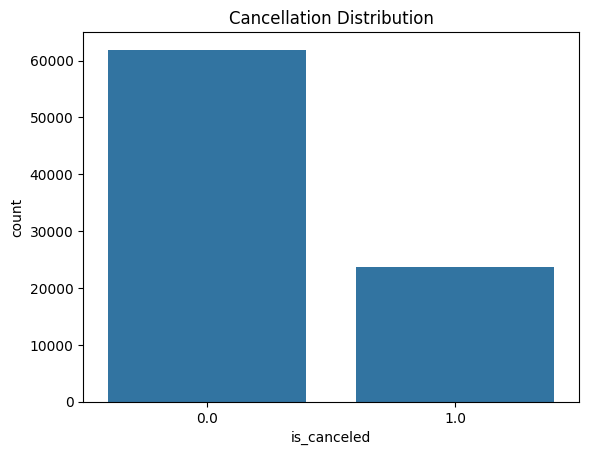

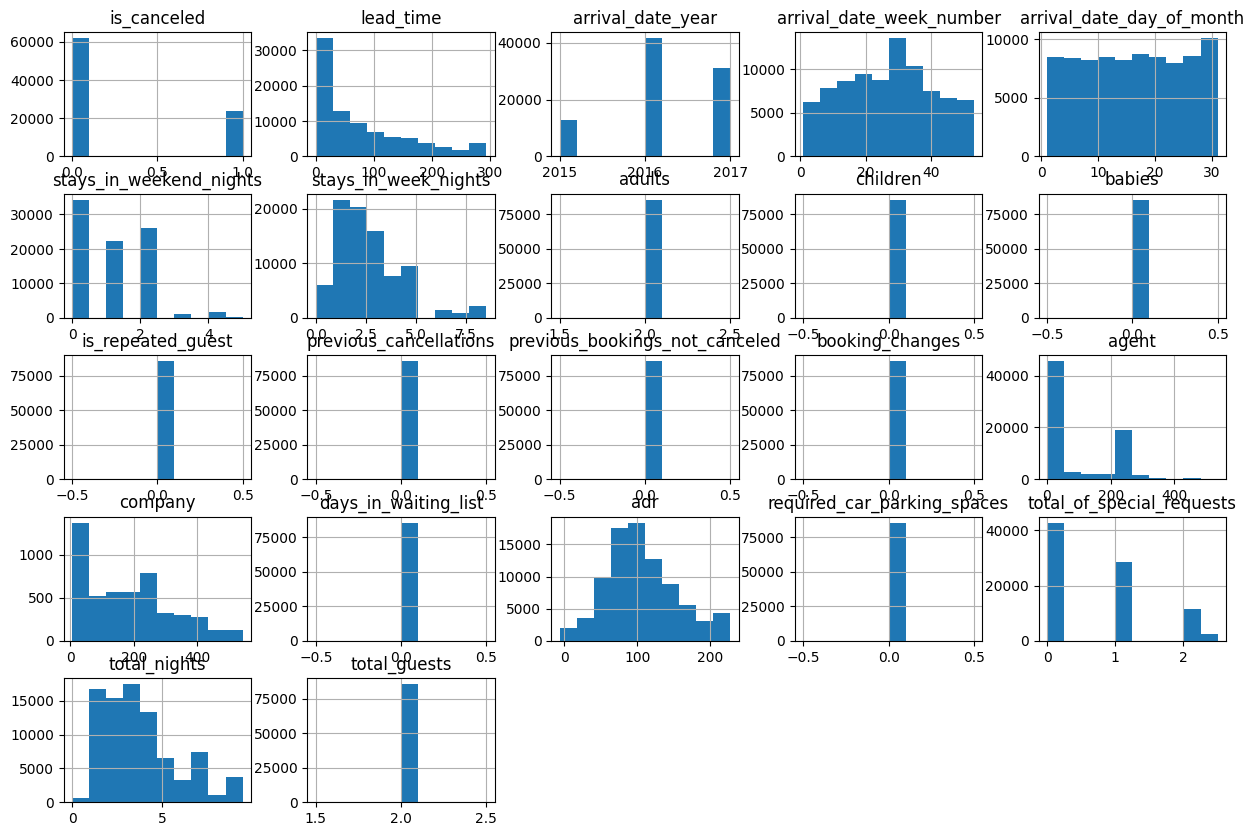

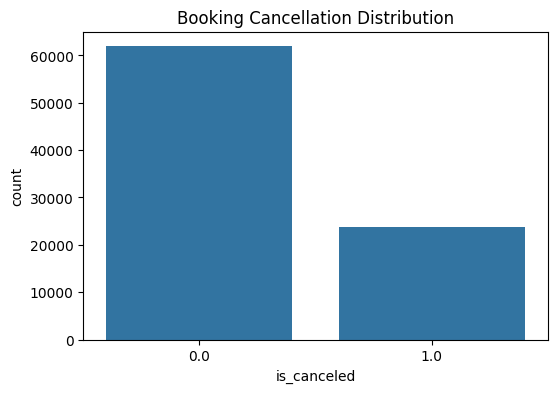

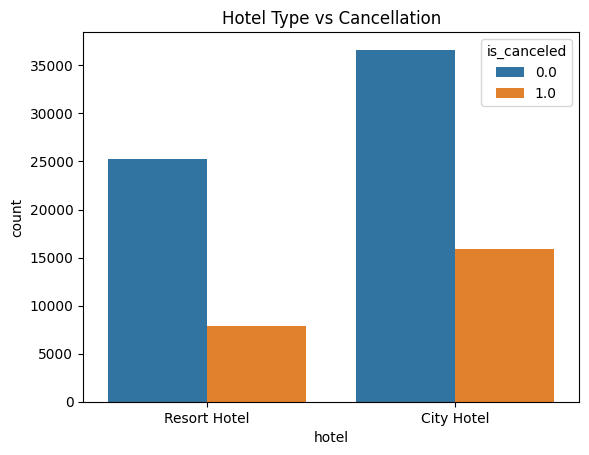

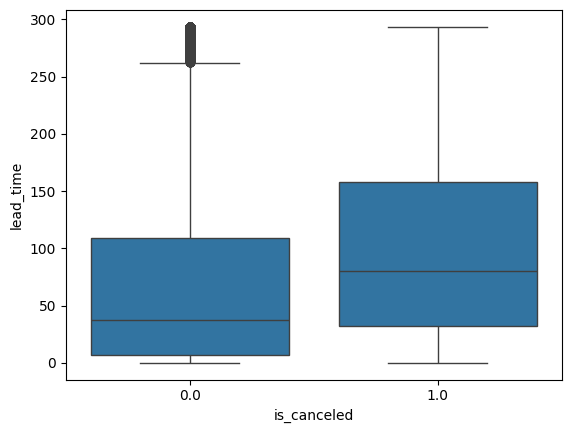

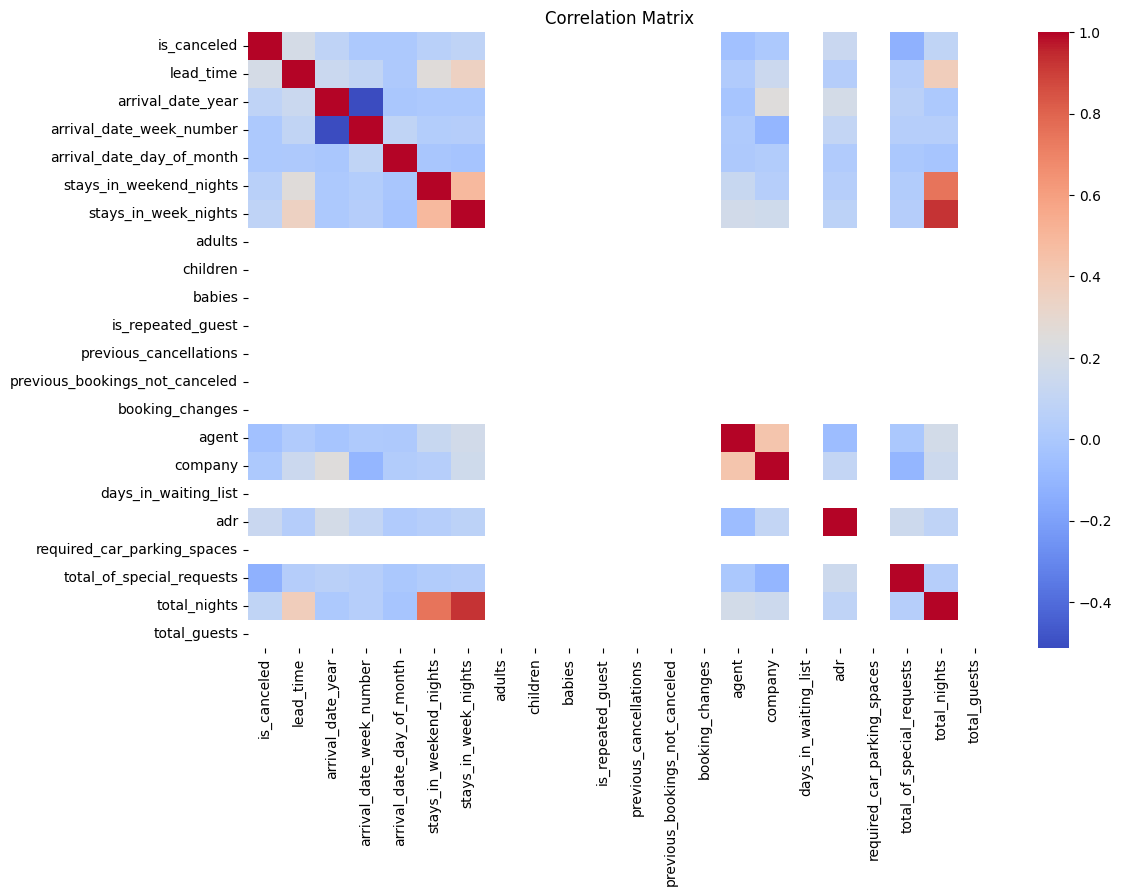

In [9]:
# Exploratory Data Analysis (EDA)

# Target variable distribution
sns.countplot(x='is_canceled', data=df)
plt.title("Cancellation Distribution")
plt.show()

# Numerical distribution
df.hist(figsize=(15,10))
plt.show()

# Univariate Analysis
plt.figure(figsize=(6,4))
sns.countplot(x='is_canceled', data=df)
plt.title("Booking Cancellation Distribution")
plt.show()

# Bivariate Analysis
# Hotel vs cancellation
if 'hotel' in df.columns:
    sns.countplot(x='hotel', hue='is_canceled', data=df)
    plt.title("Hotel Type vs Cancellation")
    plt.show()

# Lead time vs cancellation
if 'lead_time' in df.columns:
    sns.boxplot(x='is_canceled', y='lead_time', data=df)
    plt.show()

# Multivariate Analysis
# Correlation Heatmap
plt.figure(figsize=(12,8))
corr = df.corr(numeric_only=True)
sns.heatmap(corr, cmap='coolwarm')
plt.title("Correlation Matrix")
plt.show()

In [10]:
# Feature Encoding (Encode Categorical Variables)
label_enc = LabelEncoder()

for col in df.select_dtypes(include='object').columns:
    df[col] = label_enc.fit_transform(df[col])


In [25]:
# Train Test Split

# Define features and target
X = df.drop('is_canceled', axis=1)
y = df['is_canceled']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

In [26]:
# Feature Scaling
from sklearn.impute import SimpleImputer

# Imputer (fills missing values safely)
imputer = SimpleImputer(strategy='median')

X_train = imputer.fit_transform(X_train)
X_test = imputer.transform(X_test)

# Scaling
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [16]:
# Model Training

# Logistic Regression
lr = LogisticRegression(max_iter=1000)
lr.fit(X_train, y_train)

# Random Forest
rf = RandomForestClassifier(n_estimators=100, random_state=42)
rf.fit(X_train, y_train)

,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstrap: bool, default=TrueWhether bootstrap samples are used when building trees. If False, thewhole dataset is used to build each tree.",True
,"oob_score oob_score: bool or callable, default=FalseWhether to use out-of-bag samples to estimate the generalization score.By default, :func:`~sklearn.metrics.accuracy_score` is used.Provide a callable with signature `metric

Logistic Regression Performance:
Accuracy: 0.9878027429238401
Precision: 1.0
Recall: 0.9560092612081666
F1 Score: 0.9775099537286129


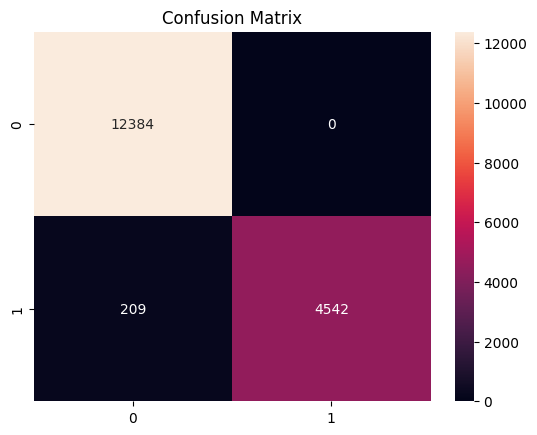


Random Forest Performance:
Accuracy: 0.9998832798365918
Precision: 1.0
Recall: 0.9995790359924226
F1 Score: 0.9997894736842106


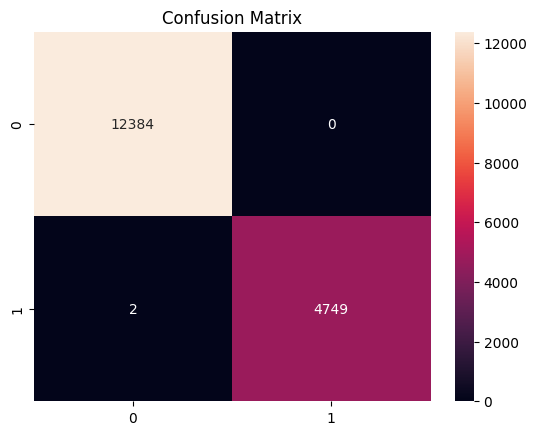

In [17]:
# Model Evaluation

# MODEL EVALUATION FUNCTION
def evaluate_model(model, X_test, y_test):
    y_pred = model.predict(X_test)

    print("Accuracy:", accuracy_score(y_test, y_pred))
    print("Precision:", precision_score(y_test, y_pred))
    print("Recall:", recall_score(y_test, y_pred))
    print("F1 Score:", f1_score(y_test, y_pred))

    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d')
    plt.title("Confusion Matrix")
    plt.show()

# EVALUATE MODELS
print("Logistic Regression Performance:")
evaluate_model(lr, X_test, y_test)

print("\nRandom Forest Performance:")
evaluate_model(rf, X_test, y_test)

In [23]:
# Classification Report
from sklearn.metrics import classification_report
def evaluate_model(name, model, X_test, y_test):
    y_pred = model.predict(X_test)

    print(f"\n{name} Performance:")

    # Accuracy
    acc = accuracy_score(y_test, y_pred)
    print("Accuracy:", acc)

    # Full classification report
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    return acc

# Evaluate both models
lr_acc = evaluate_model("Logistic Regression", lr, X_test, y_test)
rf_acc = evaluate_model("Random Forest", rf, X_test, y_test)


Logistic Regression Performance:
Accuracy: 0.9878027429238401

Classification Report:
              precision    recall  f1-score   support

         0.0       0.98      1.00      0.99     12384
         1.0       1.00      0.96      0.98      4751

    accuracy                           0.99     17135
   macro avg       0.99      0.98      0.98     17135
weighted avg       0.99      0.99      0.99     17135


Random Forest Performance:
Accuracy: 0.9998832798365918

Classification Report:
              precision    recall  f1-score   support

         0.0       1.00      1.00      1.00     12384
         1.0       1.00      1.00      1.00      4751

    accuracy                           1.00     17135
   macro avg       1.00      1.00      1.00     17135
weighted avg       1.00      1.00      1.00     17135



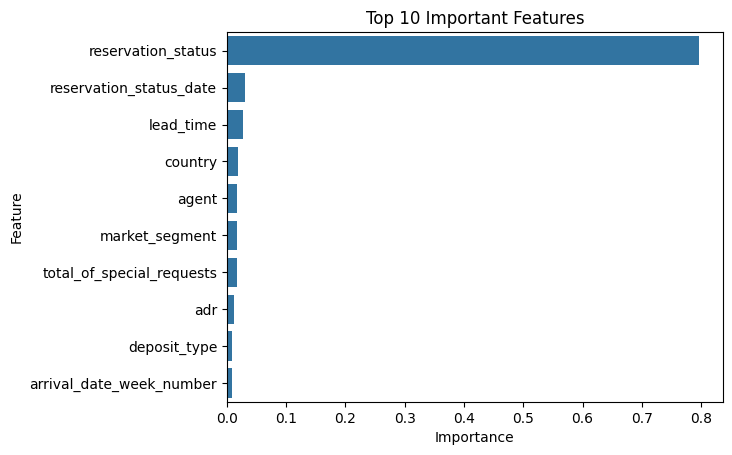

In [ ]:
# Feature Importance (Random Forest)
importances = rf.feature_importances_
features = df.drop('is_canceled', axis=1).columns

feat_df = pd.DataFrame({
    'Feature': features,
    'Importance': importances
}).sort_values(by='Importance', ascending=False)

sns.barplot(x='Importance', y='Feature', data=feat_df.head(10))
plt.title("Top 10 Important Features")
plt.show()